# H4-2: top-spending group x new/reactivated cross-analysis

**Purpose**: H4-1 confirmed that "the sales increase was driven by the remaining 80% of households".
Check whether this growth was (a) filled by new/reactivated households entering, or (b) natural growth of households that were already there.

**Label definitions (agreed criteria; when the team finalizes them tomorrow, only these cells need editing)**
- New: a household whose first purchase day is after the start of the stable window (not yet a customer when the stable window started)
- Reactivated: not new, and has at some point had a purchase gap of 13 weeks (91 days) or more
- Existing: a household that meets neither of the two conditions above

**Difference from H4-1**: the `panel` of H4-1 was a narrow sample that kept only households with transactions in both the early and late windows.
New/reactivated households by definition may have no transactions in the early window, so here we widen it to **all households present in the stable window** and rebuild.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import stats

candidates = ["Malgun Gothic", "NanumGothic", "AppleGothic"]
available = {f.name for f in fm.fontManager.ttflist}
font_name = next((c for c in candidates if c in available), None)
if font_name:
    plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False

pd.set_option('display.max_columns', 100)

from config import DATA_DIR, OUT_DIR, INTERMEDIATE_DIR, FIG_DIR, SEED

tx = pd.read_csv(DATA_DIR / "transaction_data.csv")

STABLE_MIN_WEEK = 17
STABLE_MAX_WEEK = 99
EARLY_N = 10
TOP_X_PCT = 20
REACTIVATION_GAP_DAYS = 13 * 7  # 13 weeks = 91 days

tx_stable = tx[(tx["WEEK_NO"] >= STABLE_MIN_WEEK) & (tx["WEEK_NO"] <= STABLE_MAX_WEEK)].copy()
print(f"Households in the stable window: {tx_stable['household_key'].nunique():,}")


Households in the stable window: 2,492


## 1. Identify new households

Take each household's first purchase day over the whole observation period (tx, all of DAY 1-711), and classify households whose first purchase is after the start of the stable window (week 17) as new.

In [2]:
# Check the start day of the stable window (as a DAY)
stable_start_day = tx.loc[tx["WEEK_NO"] >= STABLE_MIN_WEEK, "DAY"].min()
print(f"Start of the stable window (week {STABLE_MIN_WEEK}): DAY {stable_start_day}")

# First purchase day per household over the whole observation period
first_purchase_day = tx.groupby("household_key")["DAY"].min().rename("first_purchase_day")

is_new = first_purchase_day > stable_start_day
print(f"\nNew households: {is_new.sum():,} / {len(first_purchase_day):,} in total")


Start of the stable window (week 17): DAY 111

New households: 209 / 2,500 in total


## 2. Identify reactivated households

Among households that are not new, those that at some point in the whole observation period had a purchase gap of 13 weeks (91 days) or more.
(Reuses the same calculation as in gap_analysis.ipynb)

In [3]:
purchase_days = (
    tx[["household_key", "DAY"]]
    .drop_duplicates()
    .sort_values(["household_key", "DAY"], kind="stable")
)
purchase_days["prev_day"] = purchase_days.groupby("household_key")["DAY"].shift(1)
purchase_days["gap_days"] = purchase_days["DAY"] - purchase_days["prev_day"]

max_gap_days = purchase_days.groupby("household_key")["gap_days"].max().rename("max_gap_days")
max_gap_days = max_gap_days.fillna(0)  # a single transaction means no gap, so treat as 0

has_long_gap = max_gap_days >= REACTIVATION_GAP_DAYS
print(f"Households with a gap of 13 weeks or more: {has_long_gap.sum():,}")


Households with a gap of 13 weeks or more: 789


## 3. Label into three categories (check they are mutually exclusive and exhaustive)

Priority: new -> reactivated -> existing (a household that is not new but has a history of a long gap is reactivated)

In [4]:
labels = pd.DataFrame(index=first_purchase_day.index)
labels["is_new"] = is_new
labels["has_long_gap"] = has_long_gap.reindex(labels.index).fillna(False)

def classify(row):
    if row["is_new"]:
        return "new"
    elif row["has_long_gap"]:
        return "reactivated"
    else:
        return "existing"

labels["customer_type"] = labels.apply(classify, axis=1)

print("Households by customer type (whole observation period)")
print(labels["customer_type"].value_counts())
print(f"\nTotal check: {labels['customer_type'].value_counts().sum():,} (should equal all {len(labels):,} households)")


Households by customer type (whole observation period)
customer_type
existing       1565
reactivated     726
new             209
Name: count, dtype: int64

Total check: 2,500 (should equal all 2,500 households)


In [5]:
# --- source CSVs: status labels over all 2,500 households
_t_en = {"existing": "existing", "reactivated": "reactivated", "new": "new"}  # internal labels are already the English names written to the CSVs
_s = labels["customer_type"].value_counts()
_status = pd.DataFrame({"customer_type": [_t_en[k] for k in _s.index], "n_households": _s.values})
_status["pct"] = _status["n_households"] / len(labels) * 100
_status = pd.concat([_status, pd.DataFrame([{"customer_type": "total", "n_households": len(labels), "pct": 100.0}])])
_status.to_csv(OUT_DIR / "h4_2_status_counts.csv", index=False)
pd.DataFrame([{
    "stable_start_day": stable_start_day, "n_new": int(is_new.sum()), "n_long_gap_any": int(has_long_gap.sum()),
    "reactivation_gap_days": REACTIVATION_GAP_DAYS,
}]).to_csv(OUT_DIR / "h4_2_label_inputs.csv", index=False)

## 4. Early-window spending on the stable-window basis + top 20% group (wide dataset)

For all households present in the stable window, compute spending in the early window (weeks 17-26).
Households with no transactions in the early window (new / late-reactivated, etc.) are treated as spending 0 and automatically fall into the remaining 80%.

In [6]:
stable_households = np.sort(tx_stable["household_key"].unique())

early_window = tx_stable[
    (tx_stable["WEEK_NO"] >= STABLE_MIN_WEEK) &
    (tx_stable["WEEK_NO"] < STABLE_MIN_WEEK + EARLY_N)
]
sales_early_full = early_window.groupby("household_key")["SALES_VALUE"].sum()

# Wide panel: all households present in the stable window, early spending filled with 0
panel_wide = pd.DataFrame(index=stable_households)
panel_wide["sales_early"] = sales_early_full.reindex(panel_wide.index).fillna(0)
panel_wide = panel_wide.join(labels[["customer_type"]], how="left")

print(f"Households in the wide panel: {len(panel_wide):,}")
print(f"customer_type missing (unlabeled households): {panel_wide['customer_type'].isna().sum()}")

# Top 20% cutoff (on the whole wide panel, including households with zero early spending)
cutoff_value = panel_wide["sales_early"].quantile(1 - TOP_X_PCT/100)
panel_wide["group"] = np.where(panel_wide["sales_early"] >= cutoff_value, "top 20%", "remaining 80%")

print(f"\nTop 20% cutoff (early spending): {cutoff_value:.2f}")
print(panel_wide["group"].value_counts())


Households in the wide panel: 2,492
customer_type missing (unlabeled households): 0

Top 20% cutoff (early spending): 535.29
group
remaining 80%    1993
top 20%           499
Name: count, dtype: int64


In [7]:
# --- source CSVs: wide panel summary and the households excluded from it
_t_en = {"existing": "existing", "reactivated": "reactivated", "new": "new"}  # internal labels are already the English names written to the CSVs
pd.DataFrame([{
    "n_all_households": len(labels), "n_panel_wide": len(panel_wide),
    "n_excluded": len(labels) - len(panel_wide), "cutoff_value": cutoff_value,
    "n_top": int((panel_wide["group"] == "top 20%").sum()), "n_rest": int((panel_wide["group"] == "remaining 80%").sum()),
    "n_tied_at_cutoff": int((panel_wide["sales_early"] == cutoff_value).sum()),
}]).to_csv(OUT_DIR / "h4_2_panel_summary.csv", index=False)
_excl_keys = labels.index.difference(panel_wide.index)
_span = tx.groupby("household_key").agg(first_day=("DAY", "min"), last_day=("DAY", "max"),
                                         first_week=("WEEK_NO", "min"), last_week=("WEEK_NO", "max"),
                                         n_rows=("DAY", "size"))
_excl = _span.loc[_excl_keys].join(labels["customer_type"].map(_t_en)).rename_axis("household_key").reset_index()
_excl.to_csv(INTERMEDIATE_DIR / "h4_2_excluded_households.csv", index=False)
_excl["side"] = np.where(_excl["last_week"] < STABLE_MIN_WEEK, "before_week17_only",
                         np.where(_excl["first_week"] > STABLE_MAX_WEEK, "after_week99_only", "both_sides"))
_by = _excl.groupby("customer_type").agg(n_households=("household_key", "size"), first_week_min=("first_week", "min"),
                                         last_week_max=("last_week", "max")).reset_index()
_side = pd.crosstab(_excl["customer_type"], _excl["side"]).reindex(
    columns=["before_week17_only", "after_week99_only", "both_sides"], fill_value=0).reset_index()
_by.merge(_side, on="customer_type").to_csv(OUT_DIR / "h4_2_excluded_by_type.csv", index=False)


## 5. Build the 2x2 cross-tab

Combine new + reactivated into one, make the 2x2 table as originally planned, and also check the original three-category (new / reactivated / existing) cross-tab for reference.

In [8]:
# For reference: the original three-category cross-tab
crosstab_3cat = pd.crosstab(panel_wide["group"], panel_wide["customer_type"])
print("For reference: three-category cross-tab")
print(crosstab_3cat)


For reference: three-category cross-tab
customer_type  existing  new  reactivated
group                                    
remaining 80%      1127  175          691
top 20%             431   34           34


In [9]:
# 2x2 cross-tab with new + reactivated combined
panel_wide["new_or_reactivated"] = panel_wide["customer_type"].isin(["new", "reactivated"])
panel_wide["cohort"] = np.where(panel_wide["new_or_reactivated"], "new or reactivated", "existing")

crosstab_2x2 = pd.crosstab(panel_wide["group"], panel_wide["cohort"])
print("2x2 cross-tab (households)")
print(crosstab_2x2)

print("\nRow percentages (%): share of new/reactivated within each spending group")
print((crosstab_2x2.div(crosstab_2x2.sum(axis=1), axis=0) * 100).round(1))


2x2 cross-tab (households)
cohort         existing  new or reactivated
group                                      
remaining 80%      1127                 866
top 20%             431                  68

Row percentages (%): share of new/reactivated within each spending group
cohort         existing  new or reactivated
group                                      
remaining 80%      56.5                43.5
top 20%            86.4                13.6


In [10]:
# --- source CSVs: contingency tables (3-category and 2x2)
_g_en = {"top 20%": "top20", "remaining 80%": "rest80"}
_t_en = {"existing": "existing", "reactivated": "reactivated", "new": "new"}  # internal labels are already the English names written to the CSVs
_c_en = {"existing": "existing", "new or reactivated": "new_or_reactivated"}
crosstab_3cat.rename(index=_g_en, columns=_t_en).rename_axis(index="group", columns="customer_type") \
    .stack().rename("n_households").reset_index().to_csv(OUT_DIR / "h4_2_crosstab_3cat.csv", index=False)
_x = crosstab_2x2.rename(index=_g_en, columns=_c_en).rename_axis(index="group", columns="cohort")
_long = _x.stack().rename("n_households").reset_index()
_long["row_pct"] = _long["n_households"] / _long.groupby("group")["n_households"].transform("sum") * 100
_long.to_csv(OUT_DIR / "h4_2_crosstab_2x2.csv", index=False)

## 6. Check the expected frequencies, then decide the test

If every cell has an expected frequency >= 5, use chi-square; if any is < 5, use Fisher's exact test.

In [11]:
chi2_stat, chi2_p, dof, expected = stats.chi2_contingency(crosstab_2x2)

print("Expected-frequency table")
print(pd.DataFrame(expected, index=crosstab_2x2.index, columns=crosstab_2x2.columns).round(1))

min_expected = expected.min()
print(f"\nMinimum expected frequency: {min_expected:.2f}")

use_fisher = min_expected < 5
print(f"-> {'Use Fisher exact test' if use_fisher else 'Chi-square test can be used'}")


Expected-frequency table
cohort         existing  new or reactivated
group                                      
remaining 80%    1246.0               747.0
top 20%           312.0               187.0

Minimum expected frequency: 187.02
-> Chi-square test can be used


## 7. Run the test + effect size

- With chi-square: Cramér's V
- With Fisher's exact: odds ratio + 95% CI (based on the normal approximation of the log odds ratio)

In [12]:
n_total = crosstab_2x2.values.sum()

if use_fisher:
    # 2x2 table order: crosstab_2x2 rows = [remaining 80%, top 20%], columns = [existing, new or reactivated] (note the alphabetical sort order)
    print("Check the cross-tab row/column order:")
    print(crosstab_2x2)

    odds_ratio, p_value = stats.fisher_exact(crosstab_2x2.values)

    # Odds-ratio confidence interval (Haldane-Anscombe correction: +0.5 in case of a zero cell)
    a, b = crosstab_2x2.values[0]
    c, d = crosstab_2x2.values[1]
    if 0 in [a, b, c, d]:
        a, b, c, d = a+0.5, b+0.5, c+0.5, d+0.5
        odds_ratio = (a*d) / (b*c)

    log_or = np.log(odds_ratio)
    se_log_or = np.sqrt(1/a + 1/b + 1/c + 1/d)
    ci_low = np.exp(log_or - 1.96*se_log_or)
    ci_high = np.exp(log_or + 1.96*se_log_or)

    print(f"\n[Fisher's exact test]")
    print(f"p-value = {p_value:.6f}")
    print(f"Odds ratio (OR) = {odds_ratio:.3f}")
    print(f"95% CI = ({ci_low:.3f}, {ci_high:.3f})")

else:
    n = n_total
    r, k = crosstab_2x2.shape
    cramers_v = np.sqrt(chi2_stat / (n * (min(r, k) - 1)))

    print(f"[Chi-square test of independence]")
    print(f"chi2 statistic = {chi2_stat:.3f}, dof = {dof}")
    print(f"p-value = {chi2_p:.6f}")
    print(f"Effect size (Cramér's V) = {cramers_v:.3f}")


[Chi-square test of independence]
chi2 statistic = 150.225, dof = 1
p-value = 0.000000
Effect size (Cramér's V) = 0.246


In [13]:
# --- source CSV: chi-square test of the 2x2 table
pd.DataFrame([{
    "n": int(n_total), "chi2": chi2_stat, "dof": dof, "p_value": chi2_p, "cramers_v": cramers_v,
    "min_expected": min_expected,
}]).to_csv(OUT_DIR / "h4_2_chi_square.csv", index=False)

## 8. Summary of results and interpretation guide

- If the p-value is significant (< 0.05) and in the proportion table of section 5 **the share of new/reactivated households in the top 20% is lower than in the remaining 80%**,
  -> that is evidence that "the remaining 80%, which drove the sales increase, contains relatively more new/reactivated households"
- Conversely, if there is no big difference in the proportions or it is not significant,
  -> the growth of the remaining 80% is more likely natural spending growth of existing households than an inflow of new/reactivated ones

In [14]:
print("Final proportion comparison (share of new/reactivated within each group)")
ratio_table = (crosstab_2x2.div(crosstab_2x2.sum(axis=1), axis=0) * 100).round(1)
print(ratio_table)

print(f"\nTest conclusion: {'significant (association found)' if (p_value if use_fisher else chi2_p) < 0.05 else 'not significant (insufficient evidence of an association)'}")


Final proportion comparison (share of new/reactivated within each group)
cohort         existing  new or reactivated
group                                      
remaining 80%      56.5                43.5
top 20%            86.4                13.6

Test conclusion: significant (association found)


## 9. Compute the actual contribution of new/reactivated households

So far (the 2x2 cross-tab) we only confirmed "there is an association". Here we go one step further and
**decompose directly, in money, how much of the sales increase of the remaining 80% group actually came from new/reactivated households**.

Only with this can we go beyond the correlation "many new/reactivated households are mixed in" and say "so how much did they actually contribute to the sales increase".

In [15]:
# Fill late-window spending into panel_wide and compute diff (the previous cell had only sales_early)
late_window = tx_stable[
    (tx_stable["WEEK_NO"] > STABLE_MAX_WEEK - EARLY_N) &
    (tx_stable["WEEK_NO"] <= STABLE_MAX_WEEK)
]
sales_late_full = late_window.groupby("household_key")["SALES_VALUE"].sum()

panel_wide["sales_late"] = sales_late_full.reindex(panel_wide.index).fillna(0)
panel_wide["diff"] = panel_wide["sales_late"] - panel_wide["sales_early"]

print("Final columns of panel_wide:", list(panel_wide.columns))
panel_wide[["sales_early", "sales_late", "diff", "group", "cohort", "customer_type"]].head()


Final columns of panel_wide: ['sales_early', 'customer_type', 'group', 'new_or_reactivated', 'cohort', 'sales_late', 'diff']


,sales_early,sales_late,diff,group,cohort,customer_type
1,532.58,463.77,-68.81,remaining 80%,existing,existing
2,407.38,213.67,-193.71,remaining 80%,existing,existing
3,464.58,61.85,-402.73,remaining 80%,new or reactivated,new
4,155.53,24.95,-130.58,remaining 80%,existing,existing
5,188.31,0.00,-188.31,remaining 80%,new or reactivated,reactivated


In [16]:
panel_wide.to_csv(INTERMEDIATE_DIR / "h4_2_panel_wide.csv", index_label="household_key")

### 9-1. Within the remaining 80% group: diff sum and contribution share by cohort

Take the total diff (net increase) of the whole remaining 80% group as 100%, and compute what % of it is taken by new/reactivated vs existing.

In [17]:
rest_group = panel_wide[panel_wide["group"] == "remaining 80%"].copy()

total_diff_rest = rest_group["diff"].sum()
contribution = rest_group.groupby("cohort")["diff"].agg(["sum", "mean", "median", "count"])
contribution["contribution_pct"] = (contribution["sum"] / total_diff_rest * 100).round(1)

print(f"Total net increase of the whole remaining 80% group: {total_diff_rest:,.0f}")
print()
contribution


Total net increase of the whole remaining 80% group: 193,280



,sum,mean,median,count,contribution_pct
cohort,,,,,
existing,135200.32,119.964791,51.780,1127,70.0
new or reactivated,58079.24,67.066097,10.255,866,30.0


In [18]:
# --- source CSV: contribution of each cohort to the spending increase within the rest80 group
_c_en = {"existing": "existing", "new or reactivated": "new_or_reactivated"}
_contrib = contribution.rename(index=_c_en).reset_index().rename(
    columns={"sum": "diff_sum", "contribution_pct": "contribution_pct_rounded"})
_contrib["contribution_pct"] = _contrib["diff_sum"] / total_diff_rest * 100
_contrib["headcount_pct"] = _contrib["count"] / _contrib["count"].sum() * 100
_contrib["total_diff_rest"] = total_diff_rest
_contrib.to_csv(OUT_DIR / "h4_2_contribution_rest80.csv", index=False)

### 9-2. On the whole population (top 20% + remaining 80%): contribution by cohort

Check the same thing for all stable-window households without distinguishing the groups. It shows the share that
new/reactivated households take of the "overall net increase" confirmed in H4-1.

In [19]:
total_diff_all = panel_wide["diff"].sum()
contribution_all = panel_wide.groupby("cohort")["diff"].agg(["sum", "mean", "median", "count"])
contribution_all["contribution_pct"] = (contribution_all["sum"] / total_diff_all * 100).round(1)

print(f"Total net increase of all households: {total_diff_all:,.0f}")
print()
contribution_all


Total net increase of all households: 126,232



,sum,mean,median,count,contribution_pct
cohort,,,,,
existing,95773.35,61.471983,24.345,1558,75.9
new or reactivated,30458.83,32.611167,3.025,934,24.1


In [20]:
_c_en = {"existing": "existing", "new or reactivated": "new_or_reactivated"}
_contrib_all = contribution_all.rename(index=_c_en).reset_index().rename(
    columns={"sum": "diff_sum", "contribution_pct": "contribution_pct_rounded"})
_contrib_all["contribution_pct"] = _contrib_all["diff_sum"] / total_diff_all * 100
_contrib_all["headcount_pct"] = _contrib_all["count"] / _contrib_all["count"].sum() * 100
_contrib_all["total_diff_all"] = total_diff_all
_contrib_all.to_csv(OUT_DIR / "h4_2_contribution_all.csv", index=False)

### 9-3. Statistical check of the diff distribution by cohort (within the remaining 80%, new/reactivated vs existing)

Check with a nonparametric test (Mann-Whitney U) whether "new/reactivated households really have a larger diff than existing households".
The samples are likely non-normal, so proceed after checking normality.

In [21]:
new_react_diff = rest_group.loc[rest_group["cohort"] == "new or reactivated", "diff"].values
existing_diff  = rest_group.loc[rest_group["cohort"] == "existing", "diff"].values

# Normality (for reference)
for name, arr in [("new or reactivated", new_react_diff), ("existing", existing_diff)]:
    stat, p = stats.shapiro(arr) if len(arr) < 5000 else stats.normaltest(arr)
    print(f"{name}: n={len(arr)}, normality p={p:.6f} ({'rejected' if p<0.05 else 'not rejected'})")

u_stat, p_mw = stats.mannwhitneyu(new_react_diff, existing_diff, alternative='two-sided')
n1, n2 = len(new_react_diff), len(existing_diff)
rank_biserial = 1 - (2*u_stat) / (n1*n2)
common_language = u_stat / (n1*n2)

print(f"\n[Mann-Whitney U] new or reactivated vs existing (within the remaining 80%)")
print(f"U statistic = {u_stat:.2f}, p-value = {p_mw:.6f}")
print(f"Effect size (rank-biserial) = {rank_biserial:.3f}")
print(f"Common language effect size = {common_language:.3f}")
print(f"Median diff - new or reactivated: {np.median(new_react_diff):.2f}, existing: {np.median(existing_diff):.2f}")


new or reactivated: n=866, normality p=0.000000 (rejected)
existing: n=1127, normality p=0.000000 (rejected)

[Mann-Whitney U] new or reactivated vs existing (within the remaining 80%)
U statistic = 445820.00, p-value = 0.000928
Effect size (rank-biserial) = 0.086
Common language effect size = 0.457
Median diff - new or reactivated: 10.26, existing: 51.78


In [22]:
# --- source CSVs: Mann-Whitney within rest80, and boxplot statistics for the cohort figure
from matplotlib.cbook import boxplot_stats
pd.DataFrame([{
    "n_new_or_reactivated": n1, "n_existing": n2, "u_statistic": u_stat, "p_value": p_mw,
    "rank_biserial": rank_biserial, "common_language": common_language,
    "median_new_or_reactivated": np.median(new_react_diff), "median_existing": np.median(existing_diff),
    "alpha_adj_bonferroni_4": 0.05 / 4,
}]).to_csv(OUT_DIR / "h4_2_mannwhitney.csv", index=False)
_bx, _fl = [], []
for _g, _arr in [("new_or_reactivated", new_react_diff), ("existing", existing_diff)]:
    _st = boxplot_stats(_arr)[0]
    _bx.append({"cohort": _g, "n": len(_arr), **{k: _st[k] for k in ["q1", "med", "q3", "whislo", "whishi", "mean"]}})
    _fl += [{"cohort": _g, "value": v} for v in sorted(_st["fliers"])]
pd.DataFrame(_bx).to_csv(OUT_DIR / "h4_2_cohort_boxplot_stats.csv", index=False)
pd.DataFrame(_fl).to_csv(OUT_DIR / "h4_2_cohort_boxplot_fliers.csv", index=False)

### 9-4. Visualization: compare the contribution by cohort

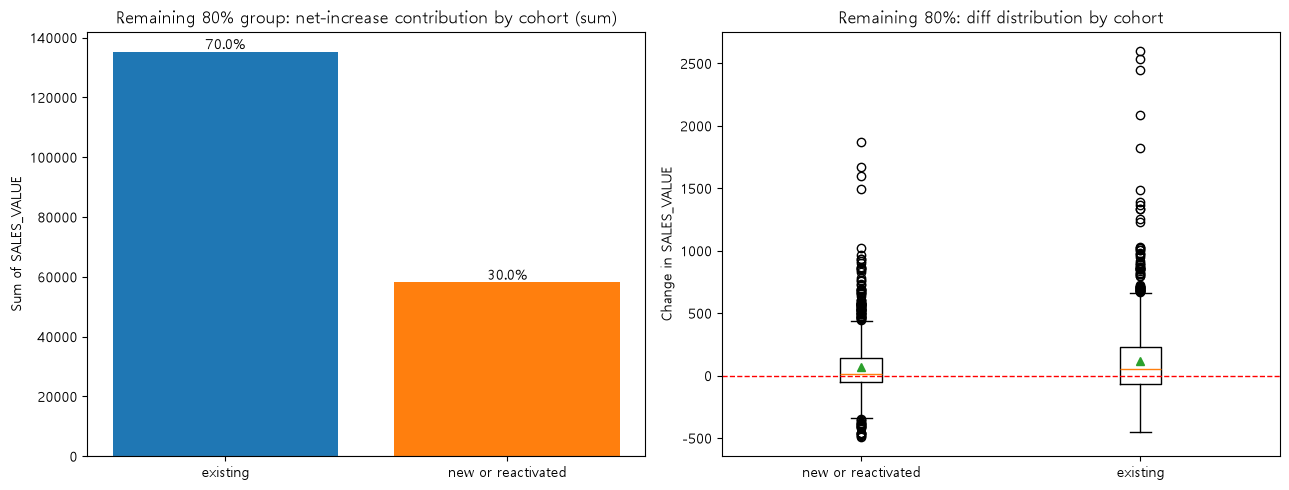

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(contribution.index, contribution["sum"], color=['C0', 'C1'])
axes[0].axhline(0, color='gray', linewidth=0.8)
axes[0].set_title("Remaining 80% group: net-increase contribution by cohort (sum)")
axes[0].set_ylabel("Sum of SALES_VALUE")

axes[0].bar_label(axes[0].containers[0], labels=[f"{v:.1f}%" for v in contribution["contribution_pct"]])

axes[1].boxplot([new_react_diff, existing_diff], tick_labels=["new or reactivated", "existing"], showmeans=True)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_title("Remaining 80%: diff distribution by cohort")
axes[1].set_ylabel("Change in SALES_VALUE")

plt.tight_layout()
plt.show()


### 9-5. Interpretation guide

- **Contribution share in 9-1**: if the share of the remaining 80%'s total net increase taken by new/reactivated households is much larger than their headcount share (43.5%),
  -> it means the contribution per household itself is large, "not just that there are many of them", which gives more weight to a causal reading
  Conversely, if the headcount share and the contribution share are similar -> it may just be a headcount effect
- **Test in 9-3**: if p < 0.05 and the median diff of new/reactivated households is significantly larger than that of existing households,
  -> there is statistical support for "new/reactivated households really grew more"
- If both are confirmed, the conclusion of H4-2 can go one step beyond "there is an association" and be described as
  "the inflow of new/reactivated households contributed substantively to the sales increase"